In [81]:
import pandas as pd
df = pd.read_csv("C:\\Users\\shahd\\Documents\\GitHub\\ai4i-predictive-maintenance\\original_data\\ai4i2020_dirty.csv")

In [83]:
print(df.head())
print(df.shape)

    UDI Product ID Type  Air temperature [K]  Process temperature [K]  \
0  6696     M21555    M                301.7                    311.0   
1  3211     M18070    M                300.3                    309.2   
2  3621     H33034    H                301.9                    311.2   
3  9117     H38530    H                297.6                    308.7   
4  1904     L49083    L                297.9                    307.6   

   Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  Machine failure  TWF  \
0                  1311.0         55.8             39.0                0    0   
1                  1364.0         47.6             45.0                0    0   
2                  1474.0         41.8             18.0                0    0   
3                  1659.0         32.1             49.0                0    0   
4                  1968.0          NaN            171.0                0    0   

   HDF  PWF  OSF  RNF  
0    0    0    0    0  
1    0    0    0    0  
2 

In [85]:
print(df.isnull().sum())
print("the duplicates summationa",df.duplicated().sum())

UDI                          0
Product ID                   0
Type                         0
Air temperature [K]        809
Process temperature [K]    807
Rotational speed [rpm]     806
Torque [Nm]                810
Tool wear [min]            808
Machine failure              0
TWF                          0
HDF                          0
PWF                          0
OSF                          0
RNF                          0
dtype: int64
the duplicates summationa 100


detect outliers


In [64]:
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Air Temperature Spread')

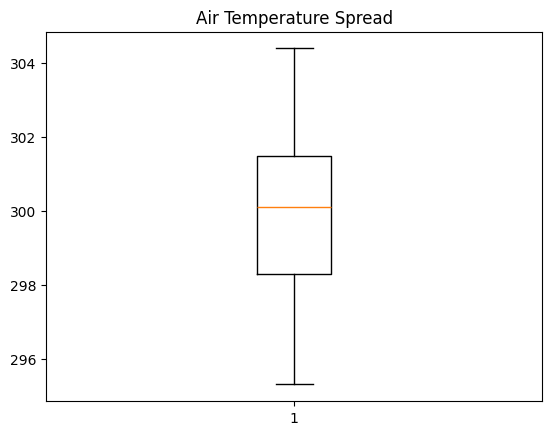

In [ ]:
plt.boxplot(df["Air temperature [K]"].dropna()) ".dropna() just ignores the null values without removing them permanently  
plt.title("Air Temperature Spread") 


Text(0.5, 1.0, 'Process Temperature Spread')

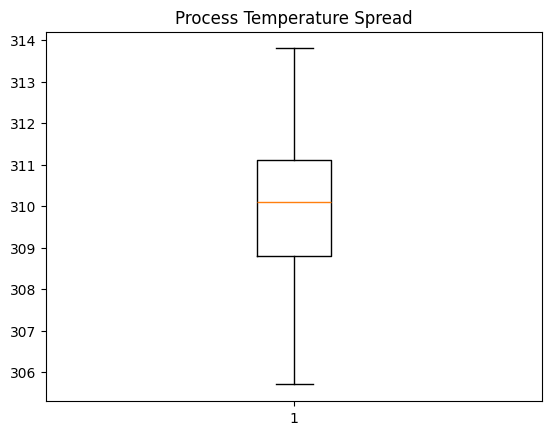

In [ ]:
plt.boxplot(df["Process temperature [K]"].dropna()) 
plt.title("Process Temperature Spread") 

Text(0.5, 1.0, 'Rotational Speed Spread')

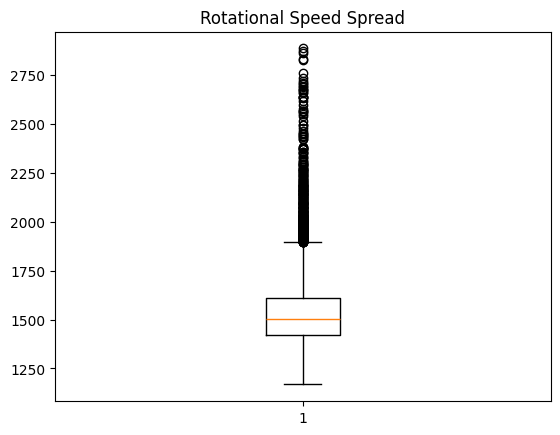

In [67]:
plt.boxplot(df["Rotational speed [rpm]"].dropna()) 
plt.title("Rotational Speed Spread")

Text(0.5, 1.0, 'Torque Spread')

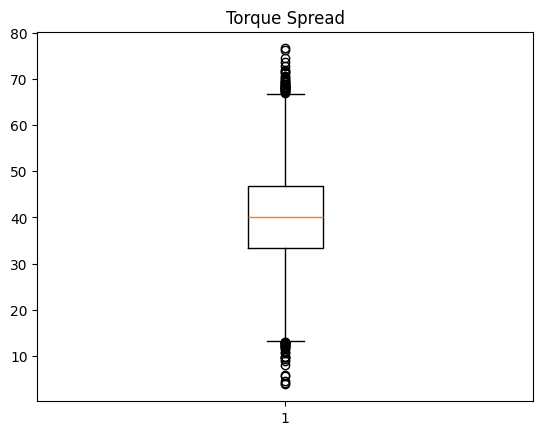

In [68]:
plt.boxplot(df["Torque [Nm]"].dropna()) 
plt.title("Torque Spread") 

Text(0.5, 1.0, 'Tool Wear Spread')

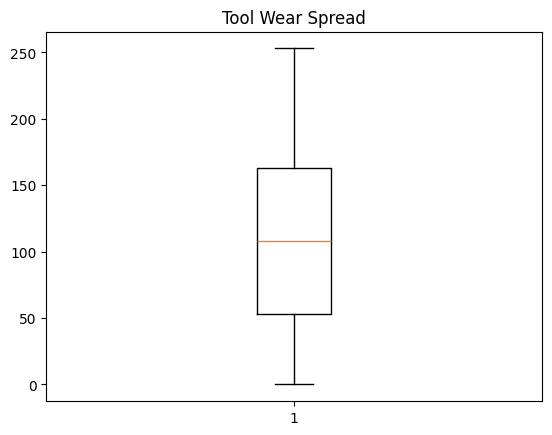

In [69]:
plt.boxplot(df["Tool wear [min]"].dropna()) 
plt.title("Tool Wear Spread") 

In [70]:
columns = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

for col in columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    outliers = df[
        (df[col] < q1 - 1.5 * iqr) |
        (df[col] > q3 + 1.5 * iqr)
    ]

    print(col, ":", len(outliers))

Air temperature [K] : 0
Process temperature [K] : 0
Rotational speed [rpm] : 394
Torque [Nm] : 66
Tool wear [min] : 0


fixing outliers

In [71]:
columns = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

for col in columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    
    iqr = q3 - q1
    
    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr
    
    df[col] = df[col].clip(
        lower=lower_limit,
        upper=upper_limit
    )

print("Outliers fixed successfully!")

Outliers fixed successfully!


In [72]:
columns = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

for col in columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    outliers = df[
        (df[col] < q1 - 1.5 * iqr) |
        (df[col] > q3 + 1.5 * iqr)
    ]

    print(col, ":", len(outliers))

Air temperature [K] : 0
Process temperature [K] : 0
Rotational speed [rpm] : 0
Torque [Nm] : 0
Tool wear [min] : 0


fixing nulls

In [73]:
columns = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

for col in columns:
    df[col] = df[col].fillna(df[col].mean())
    print(col, ":", df[col].isnull().sum())

Air temperature [K] : 0
Process temperature [K] : 0
Rotational speed [rpm] : 0
Torque [Nm] : 0
Tool wear [min] : 0


fixing duplicates 

In [ ]:
df = df.drop_duplicates()
print(df.shape)
print(df.duplicated().sum())


100
(10000, 14)
0


In [75]:
print(df.isnull().sum())
print(df.duplicated().sum())

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64
0


In [76]:
df.to_csv("cleaned_data.csv", index=False)

print("Cleaned data saved successfully!")

Cleaned data saved successfully!
